In [32]:
import numpy as np
import pandas as pd
instacart_orders = pd.read_csv('instacart_orders.csv',sep=';')
instacart_orders.sample(10)

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
120650,311429,162128,5,5,7,30.0
338060,603025,94901,1,2,14,NaN
476372,2471104,57619,1,0,11,NaN
224565,432855,131620,32,0,9,6.0
281942,1318405,136916,4,0,12,30.0
385260,1047626,9300,11,0,16,30.0
325855,585804,92240,32,0,12,7.0
166911,1917019,9341,85,1,11,2.0
428584,1089249,135922,39,1,19,10.0
350985,1546457,187576,10,6,12,7.0


In [2]:
instacart_orders.shape

(478967, 6)

In [3]:
instacart_orders.isna().sum()

,0
order_id,0
user_id,0
order_number,0
order_dow,0
order_hour_of_day,0
days_since_prior_order,28819


In [4]:
round(instacart_orders.isna().sum()/len(instacart_orders)*100,2)

,0
order_id,0.00
user_id,0.00
order_number,0.00
order_dow,0.00
order_hour_of_day,0.00
days_since_prior_order,6.02


- It is important for machine learning model building because if even one missing value is present then ML model will not work. (there is some exception present in certain algorithums which can deal missing data internally)

- If data is missing less than 5 % we should use dropna method
- If data is missing greater than 5 % but less than 80% we should use fillna method(given the feature is important).
- If data is missing gretaer than 80 to 100 % we should simply remove that feature (given the feature is not important)



# 1.The dropna() method

The dropna() method removes the rows that contains NULL values. The dropna() method returns a new DataFrame object unless the inplace parameter is set to True , in that case the dropna() method does the removing in the original DataFrame instead.

In [5]:
instacart_orders.shape

(478967, 6)

In [6]:
instacart_orders.dropna(inplace=True)

In [7]:
instacart_orders.shape

(450148, 6)

In [8]:
instacart_orders.isna().sum()

,0
order_id,0
user_id,0
order_number,0
order_dow,0
order_hour_of_day,0
days_since_prior_order,0


##Scenarios

1. We want to remove rows where even a single value is missing (axis = 0, how = any)

1. We want to remove rows where all the values are missing (axis = 0, how = all)

3. We want to remove columns where even a single value is missing (axis = 1, how = any)

4. We want to remove columns where all the values are missing (axis = 1, how = all)

In [9]:
instacart_orders.dropna(axis=1,how='any',inplace=True)
instacart_orders.shape

(450148, 6)

# 2.The fillna() method
The fillna() method replaces the NULL values with a specified value. The fillna() method returns a new DataFrame object unless the inplace parameter is set to True , in that case the fillna() method does the replacing in the original DataFrame instead.

In [15]:
mean_value = instacart_orders['days_since_prior_order'].mean()
mean_value

np.float64(11.101750979677794)

In [19]:
instacart_orders['days_since_prior_order'] = instacart_orders['days_since_prior_order'].fillna(value=mean_value)
instacart_orders.sample(30)

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
313237,566949,181933,5,2,15,30.000000
234630,908322,66102,4,6,14,8.000000
345778,3359524,97392,6,0,14,30.000000
215002,2657406,127593,32,2,11,18.000000
91840,1145980,165479,60,2,9,7.000000
366324,365268,197303,56,3,10,2.000000
263944,3048262,61500,43,6,12,7.000000
172126,2963661,136543,30,5,15,4.000000
32555,996907,95526,7,1,13,5.000000
164089,586766,62558,22,4,9,12.000000


In [21]:
instacart_orders.isna().sum()

,0
order_id,0
user_id,0
order_number,0
order_dow,0
order_hour_of_day,0
days_since_prior_order,0


In [29]:
instacart_orders['days_since_prior_order'].median()

7.0

In [28]:
median_value = instacart_orders['days_since_prior_order'].median()
instacart_orders['days_since_prior_order'] = instacart_orders['days_since_prior_order'].fillna(value=median_value)
instacart_orders.sample(30)

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
363300,35813,73645,81,0,20,5.0
226806,1723149,173545,9,1,9,7.0
389877,1488446,82375,1,6,12,7.0
378498,2464787,74889,31,0,9,8.0
425808,1370052,50380,1,5,9,7.0
209865,1587734,166795,11,4,16,5.0
28302,2066338,156356,38,0,16,6.0
124113,2286662,188014,2,5,15,3.0
184317,880921,62473,10,4,15,6.0
446013,270388,168845,3,3,17,4.0


<Axes: ylabel='Density'>

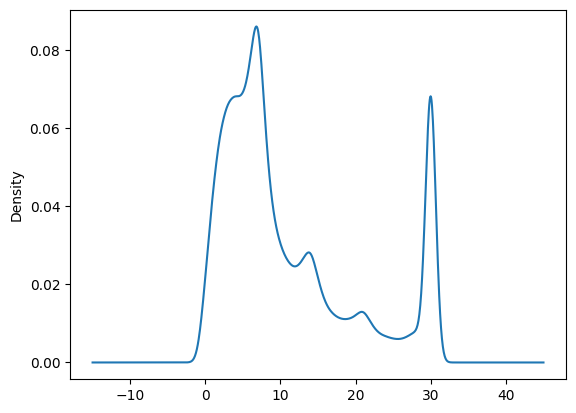

In [3]:
instacart_orders['days_since_prior_order'].plot(kind='kde')

In [7]:
instacart_orders['days_since_prior_order'].mode()

,days_since_prior_order
0,30.0


In [12]:
mode_value = instacart_orders['days_since_prior_order'].mode()
instacart_orders['days_since_prior_order'] = instacart_orders['days_since_prior_order'].fillna(value=mode_value)
instacart_orders.sample(30)

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
943,37731,152300,33,2,18,6.0
281862,2460420,55342,11,0,13,6.0
160468,1095291,133532,52,6,13,5.0
391747,3179548,18144,8,5,9,5.0
315611,3210135,40775,2,3,19,2.0
310758,3269000,56969,1,4,5,NaN
276497,1236123,55226,46,0,12,3.0
390653,717323,143359,11,3,16,9.0
313043,775395,6859,3,3,16,25.0
234025,1769273,204082,3,4,10,22.0


**in fillna function the axis value by default is none we can change it to 0 or 1 for rows and columns specifically**

In [14]:
instacart_orders.fillna(0,inplace=True)

In [19]:
instacart_orders.sample(30)

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
28238,2273072,110547,10,4,14,9.0
352607,1000518,116105,19,0,13,6.0
148922,1227132,79990,6,2,17,5.0
70875,1846597,29138,11,6,12,0.0
450014,3405447,114434,14,6,17,16.0
182844,580389,151380,3,1,11,30.0
402667,7835,97593,15,4,20,7.0
238671,2640620,85690,83,4,12,2.0
167270,3225711,35771,37,1,9,7.0
388023,1857768,52889,15,2,8,7.0


In [27]:
instacart_orders.fillna('missing value',inplace=True)

/tmp/ipython-input-3297502212.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'missing value' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  instacart_orders.fillna('missing value',inplace=True)


In [30]:
instacart_orders.head(30)

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1515936,183418,11,6,13,30.0
1,1690866,163593,5,5,12,9.0
2,1454967,39980,4,5,19,2.0
3,1768857,82516,56,0,20,10.0
4,3007858,196724,2,4,12,17.0
5,1843871,20084,5,0,11,15.0
6,2511640,148233,40,3,8,2.0
7,2521283,97711,2,0,18,22.0
8,2266494,34954,40,5,15,4.0
9,446014,15356,2,4,8,10.0


In [31]:
instacart_orders.fillna(method='ffill',inplace=True)
instacart_orders.head(30)

/tmp/ipython-input-432703419.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  instacart_orders.fillna(method='ffill',inplace=True)


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1515936,183418,11,6,13,30.0
1,1690866,163593,5,5,12,9.0
2,1454967,39980,4,5,19,2.0
3,1768857,82516,56,0,20,10.0
4,3007858,196724,2,4,12,17.0
5,1843871,20084,5,0,11,15.0
6,2511640,148233,40,3,8,2.0
7,2521283,97711,2,0,18,22.0
8,2266494,34954,40,5,15,4.0
9,446014,15356,2,4,8,10.0


In [33]:
instacart_orders.fillna(method='bfill',inplace=True)
instacart_orders.head(30)

/tmp/ipython-input-4016487588.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  instacart_orders.fillna(method='bfill',inplace=True)


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1515936,183418,11,6,13,30.0
1,1690866,163593,5,5,12,9.0
2,1454967,39980,4,5,19,2.0
3,1768857,82516,56,0,20,10.0
4,3007858,196724,2,4,12,17.0
5,1843871,20084,5,0,11,15.0
6,2511640,148233,40,3,8,2.0
7,2521283,97711,2,0,18,22.0
8,2266494,34954,40,5,15,4.0
9,446014,15356,2,4,8,10.0


- **The difficult thing in handling missing data is to identify the method we sshould use for the nature of missing data present in our dataset!**

It is decided by two things

- domain knowledge
- Statistical knowledge